<a href="https://colab.research.google.com/github/Zhengdao-Lu/Problem-Set-5-Econ_3916_PS5.ipynb/blob/main/Econ_3916_PS5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Econ 3916 PS5
## Evaluating a loan default model

Approving everyone got 93.37% accuracy on the 3,000 simulated test applications.
LASSO got the same accuracy at a 50% cutoff and caught just 3 of the 199 defaults.
I used the validation set to choose a lower cutoff, allowing for a flat
\$150 reputation cost each time the model turned down a good applicant.
At **10.23%**, LASSO caught 100 defaults and brought the test cost down from
**\$787.11 to \$616.87 per application**.

## Phase 1. The approve-all baseline

### 1.1 Simulating and splitting the data

In this simulation, a label of 1 means the applicant would default if the
lender made the loan. A model prediction of 1 tells the lender to decline.
I use the first five features to set default risk and generate the last
five independently as noise. I set the intercept before drawing the
outcomes to get a default rate near 7%.

Before looking at the results, I set aside 20% for testing. I split off
another 20% of the original data to choose the cutoff and used the
remaining 60% to fit and tune the models. I stratified both splits
by default status.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

from scipy.special import expit
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, auc, confusion_matrix, f1_score, precision_recall_curve,
    precision_score, recall_score, roc_auc_score, roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

seed = 391605
n = 15_000
rng = np.random.default_rng(seed)

# Generate the five predictors that affect default risk.
income = rng.lognormal(np.log(66_000), 0.48, n).clip(18_000, 250_000)
dti = 0.08 + 0.62 * rng.beta(2.4, 4.0, n)
history = rng.gamma(3.5, 3.5, n).clip(1, 38).round(1)
delinquencies = rng.poisson(0.40, n).clip(0, 5)
amount = (0.20 * income + rng.normal(3_500, 6_500, n)).clip(2_000, 55_000).round(-2)
income = income.round()

X = pd.DataFrame({
    "income": income,
    "debt_to_income": dti,
    "credit_history_years": history,
    "prior_delinquencies": delinquencies,
    "loan_amount": amount,
})

# Add five noise columns. They do not enter the default formula below.
X["intake_batch"] = rng.integers(1, 201, n)
X["form_version"] = rng.integers(1, 4, n)
X["paperless_opt_in"] = rng.binomial(1, 0.55, n)
X["queue_wait_seconds"] = rng.lognormal(3.3, 0.65, n)
X["submission_minute"] = rng.integers(0, 60, n)

log_odds = (
    -3.53
    - 0.42 * np.log(income / 66_000) / 0.48
    + 0.80 * (dti - 0.30) / 0.12
    - 0.47 * (history - 12) / 8
    + 0.80 * delinquencies
    + 0.36 * (amount - 16_000) / 9_000
    + 0.22 * ((dti > 0.50) & (delinquencies > 0))
)
y = pd.Series(rng.binomial(1, expit(log_odds)), name="default")

# Set aside the test set first, then split the remaining data into train/validation.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=seed, stratify=y
)
X_train, X_val, y_train, y_val = train_test_split(
    X_dev, y_dev, test_size=0.25, random_state=seed, stratify=y_dev
)

print(f"Test set: {len(y_test):,} applications, {y_test.sum()} defaults ({y_test.mean():.2%})")

Test set: 3,000 applications, 199 defaults (6.63%)


The test set had 199 defaults in 3,000 applications, or 6.63%. With
that few defaults, a model can get a high accuracy score by
predicting repayment almost every time.

### 1.2 Approving every applicant

In [ ]:
baseline = DummyClassifier(strategy="constant", constant=0)
baseline.fit(X_train, y_train)
print(f"Approve-all test accuracy: {baseline.score(X_test, y_test):.2%}")

Approve-all test accuracy: 93.37%


The approve-all rule flagged zero defaults. In the risk meeting, I would say,
“Approving every applicant already gives us 93.37% accuracy on this test set.
We need to see how many defaults the model catches and what its decisions cost.”

## Phase 2. Fitting and regularizing the models

### 2.1 Logistic regression, LASSO, and Ridge

I started with unpenalized logistic regression, then tried several penalty
strengths for LASSO (L1) and Ridge (L2). A smaller value of $C$ gives a stronger penalty.
The pipeline fits the scaler
separately inside each training fold.

I used five stratified training folds and picked the penalty with the
lowest mean log loss for each model. Log loss scores the probabilities
themselves, which matter when we use them to decide whom to decline.
I also used the mean log loss to choose between LASSO and Ridge for
the cutoff analysis.

In [ ]:
# Keep the model settings compatible with older and newer scikit-learn versions.
new_sklearn = tuple(map(int, sklearn.__version__.split(".")[:2])) >= (1, 8)
if new_sklearn:
    no_penalty = {"C": np.inf}
    penalties = {"LASSO": {"l1_ratio": 1}, "Ridge": {"l1_ratio": 0}}
else:
    no_penalty = {"penalty": None}
    penalties = {"LASSO": {"penalty": "l1"}, "Ridge": {"penalty": "l2"}}

logistic = make_pipeline(StandardScaler(), LogisticRegression(**no_penalty))
logistic.fit(X_train, y_train)

models = {"Logistic": logistic}
cv_loss = {}
coef = pd.DataFrame(index=X.columns)
c_values = np.logspace(-2.5, 1, 15)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)

for name, penalty in penalties.items():
    model = LogisticRegression(
        solver="saga", max_iter=5_000, tol=1e-5, random_state=seed, **penalty
    )
    pipeline = make_pipeline(StandardScaler(), model)
    search = GridSearchCV(
        pipeline, {"logisticregression__C": c_values},
        cv=folds, scoring="neg_log_loss", n_jobs=2,
    )
    search.fit(X_train, y_train)
    models[name] = search.best_estimator_
    cv_loss[name] = -search.best_score_
    coef[name] = models[name]["logisticregression"].coef_[0]
    print(f"{name} selected C: {search.best_params_['logisticregression__C']:.5f}")

best_name = pd.Series(cv_loss).idxmin()
best_model = models[best_name]

coef["Role"] = ["Signal"] * 5 + ["Noise"] * 5
print("LASSO zeroed:", coef.index[coef["LASSO"] == 0].tolist())
display(coef.round(5))

LASSO selected C: 0.17783
Ridge selected C: 0.10000
LASSO zeroed: []


,LASSO,Ridge,Role
income,-0.20599,-0.23301,Signal
debt_to_income,0.70656,0.70505,Signal
credit_history_years,-0.35344,-0.35932,Signal
prior_delinquencies,0.49647,0.49726,Signal
loan_amount,0.20096,0.22730,Signal
intake_batch,-0.06076,-0.07035,Noise
form_version,0.04591,0.05611,Noise
paperless_opt_in,-0.01102,-0.02127,Noise
queue_wait_seconds,-0.01312,-0.02331,Noise
submission_minute,-0.01063,-0.02100,Noise


Cross-validation picked a $C$ of 0.17783 for LASSO and 0.10000 for Ridge.
LASSO had the lower mean log loss, so I used it to choose the decline cutoff.

LASSO kept all five true predictors and all five noise features. The
noise coefficients were small, and none landed exactly at zero.
The value of $C$ that gave the best probability predictions in
cross-validation was too large to screen out the noise here.

The LASSO penalty uses the absolute value of each coefficient. It
has a corner at zero, so a predictor can stay at zero if moving
away from zero improves the fit only a little. Ridge squares the
coefficients. The penalty changes smoothly near zero, so Ridge
usually leaves small coefficients in the model. I'd use LASSO if
I expected a few predictors to do most of the work and wanted a
shorter list. I'd use Ridge if I expected several predictors to
help, especially if they were correlated and I wanted more stable
estimates. [Scikit-learn linear models guide](https://scikit-learn.org/stable/modules/linear_model.html)

### 2.2 Random forest

I fit 500 trees on bootstrap samples. For the out-of-bag (OOB) score,
each training row gets a prediction from the trees that left it out
of their samples.

In [ ]:
rf = RandomForestClassifier(
    n_estimators=500, oob_score=True, bootstrap=True, random_state=seed, n_jobs=2
)
rf.fit(X_train, y_train)
models["Random forest"] = rf

print(f"Forest OOB accuracy: {rf.oob_score_:.2%}")
print(f"Forest OOB error: {1 - rf.oob_score_:.2%}")
print(f"Forest test accuracy using rf.predict: {rf.score(X_test, y_test):.2%}")

results = []
for name, model in models.items():
    scores = model.predict_proba(X_test)[:, 1]
    predictions = scores >= 0.5
    precision, recall, _ = precision_recall_curve(y_test, scores)
    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC AUC": roc_auc_score(y_test, scores),
        "PR AUC": auc(recall, precision),
    })

metrics = pd.DataFrame(results).set_index("Model")
display(metrics[["Accuracy", "ROC AUC", "PR AUC"]].round(4))

Forest OOB accuracy: 93.54%
Forest OOB error: 6.46%
Forest test accuracy using rf.predict: 93.43%


,Accuracy,ROC AUC,PR AUC
Model,,,
Logistic,0.9333,0.7779,0.2374
LASSO,0.9337,0.7783,0.2356
Ridge,0.9333,0.7778,0.2365
Random forest,0.9343,0.6939,0.1832


The forest got about 93.5% OOB accuracy, or 6.5% OOB error. Its test
accuracy under its default prediction rule was about 93.4%. I'd
expect those numbers to be close because both use predictions
from trees that never saw the rows they were scoring. A big gap
would make me check whether the samples differ or whether I
scored them differently.

At a 0.5 cutoff, the forest caught a few more defaults than LASSO.
LASSO ranked applicants better across cutoffs. Its ROC AUC was about
0.78 and its PR AUC was 0.24. The forest got about 0.69 and 0.18 on
those measures.

### MDI and permutation importance

Mean decrease in impurity (MDI) gives a feature credit when splits
on it make the resulting groups more alike in their default
outcomes. The MDI values add up to one. For permutation importance,
I shuffle one feature at a time in the test set and average the
drop in ROC AUC across repeated shuffles.

In [ ]:
permutation = permutation_importance(
    rf, X_test, y_test, scoring="roc_auc", n_repeats=12, random_state=seed, n_jobs=2
)
importance = pd.DataFrame({
    "MDI": rf.feature_importances_,
    "Permutation (mean AUC drop)": permutation.importances_mean,
    "Role": coef["Role"],
}, index=X.columns)
display(importance.sort_values("MDI", ascending=False).round(4))

,MDI,Permutation (mean AUC drop),Role
debt_to_income,0.1841,0.1093,Signal
income,0.1321,0.0076,Signal
queue_wait_seconds,0.1293,-0.0131,Noise
credit_history_years,0.1226,-0.0093,Signal
loan_amount,0.1221,0.0045,Signal
intake_batch,0.1156,-0.0101,Noise
submission_minute,0.0977,0.0007,Noise
prior_delinquencies,0.0494,0.0663,Signal
form_version,0.0287,0.0023,Noise
paperless_opt_in,0.0183,-0.0017,Noise


Debt-to-income came first on both measures. `queue_wait_seconds`
came third on MDI with 0.129, even though I generated it as noise.
Shuffling it slightly improved test AUC on average, so its
permutation importance was −0.013. Prior delinquencies went from
eighth on MDI (0.049) to second on permutation importance (about
0.07). A feature with lots of distinct values gives a tree lots of
places to split. Some splits look good on the training data by
chance, which is how a noise feature can pick up MDI credit.

Income can help the lender estimate whether an applicant will repay.
Declining the loan does nothing to raise the applicant's income.
If the lender wants to know whether offering a smaller loan would
help, it needs evidence from changing loan offers. The importance
scores only tell us how the fitted model uses the information it has.
[Scikit-learn permutation importance guide](https://scikit-learn.org/stable/modules/permutation_importance.html)

## Phase 3. Choosing a decline cutoff

### 3.1 Test-set performance

In the confusion matrix, the rows show what happened and the
columns show what the model would do. A default in the approve
column is a false negative. I used 0.5 for accuracy, precision,
recall, and F1, and counted an exact tie as a decline. The forest's
built-in accuracy uses its own rule, which approves ties. ROC AUC
and PR AUC use the full range of scores. I used the trapezoid rule
to get the area under the precision-recall curve.

,Accuracy,Precision,Recall,F1,ROC AUC,PR AUC
Model,,,,,,
Logistic,0.9333,0.4286,0.0151,0.0291,0.7779,0.2374
LASSO,0.9337,0.5000,0.0151,0.0293,0.7783,0.2356
Ridge,0.9333,0.4286,0.0151,0.0291,0.7778,0.2365
Random forest,0.9343,0.5833,0.0352,0.0664,0.6939,0.1832


,Approve,Decline
No default,2798,3
Default,196,3


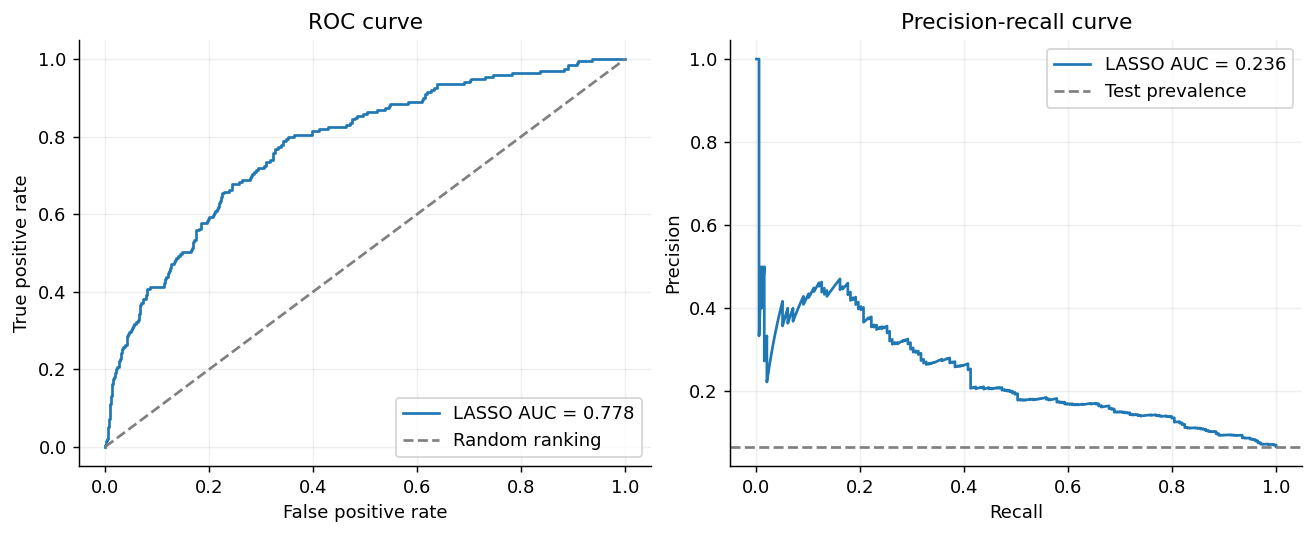

In [ ]:
test_scores = best_model.predict_proba(X_test)[:, 1]
val_scores = best_model.predict_proba(X_val)[:, 1]

display(metrics.round(4))
matrix = confusion_matrix(y_test, test_scores >= 0.5)
display(pd.DataFrame(
    matrix, index=["No default", "Default"], columns=["Approve", "Decline"]
))

fpr, tpr, _ = roc_curve(y_test, test_scores)
precision, recall, _ = precision_recall_curve(y_test, test_scores)

fig, (roc, pr) = plt.subplots(1, 2, figsize=(10, 4), layout="constrained")

roc.plot(fpr, tpr, label=f"{best_name} AUC = {auc(fpr, tpr):.3f}")
roc.plot([0, 1], [0, 1], "--", color="gray", label="Random ranking")
roc.set(title="ROC curve", xlabel="False positive rate", ylabel="True positive rate")
roc.legend(loc="lower right")

pr.plot(recall, precision, label=f"{best_name} AUC = {auc(recall, precision):.3f}")
pr.axhline(y_test.mean(), color="gray", linestyle="--", label="Test prevalence")
pr.set(title="Precision-recall curve", xlabel="Recall", ylabel="Precision")
pr.legend()
plt.show()

At 50%, LASSO let 196 of the 199 defaults through. It also approved
2,798 applicants who would repay and declined 3 who would repay.
Half the declines were defaults (50.00% precision), and the model
caught 1.51% of all defaults. F1 was 0.0293. The ROC AUC of 0.778
and PR AUC of 0.236 suggest that the model can rank applicants by
risk even though few of its scores reach 50%.

The ROC curve divides false positives by all 2,801 applicants
who would repay. That large denominator can make the false-positive
rate look small when the number of good applicants turned down is
large relative to the defaults caught. ROC AUC summarizes how
well the model ranks defaults above good loans. The
precision-recall curve tells me what share of the applicants I'd
decline would actually default at a given recall. A random
ranking has a precision baseline of 6.63%, the test default rate.

### 3.2 How much does each mistake cost?

If the lender approves a loan that defaults, I count a loss of 60% of
principal. If it turns down a good loan, I count the 8% interest
margin it would have earned plus \$150 for lost goodwill. I used
a flat amount for possible lost repeat business or referrals
because those losses can happen on a small loan, too. A correct
decision adds zero error cost.

For each cutoff, the loop adds both kinds of loss using the
requested loan amounts and divides by the number of applications.
It checks 0, 1, and every distinct score in between, since no
decisions change between scores. A score equal to the cutoff is
a decline.

I picked the cutoff on validation data and used that same number
to measure cost on the test set. I also found the cheapest cutoff
on the test curve itself as a retrospective comparison.

In [ ]:
loss_rate = 0.60
interest_margin = 0.08
reputation_cost = 150

test_amount = X_test["loan_amount"].to_numpy()
val_amount = X_val["loan_amount"].to_numpy()


def cost_at_cutoff(y, scores, amounts, cutoff, loss_rate):
    decline = scores >= cutoff
    missed_default = (y == 1) & ~decline
    good_loan_declined = (y == 0) & decline

    default_cost = (loss_rate * amounts[missed_default]).sum()
    decline_cost = (interest_margin * amounts[good_loan_declined] + reputation_cost).sum()
    return (default_cost + decline_cost) / len(y)


def threshold_costs(y, scores, amounts, loss_rate):
    # Decisions can change only when we cross a score.
    cutoffs = np.unique(np.append(scores, [0, 1]))
    costs = []
    for cutoff in cutoffs:
        costs.append(cost_at_cutoff(y, scores, amounts, cutoff, loss_rate))
    return pd.Series(costs, index=cutoffs)


val_costs = threshold_costs(y_val, val_scores, val_amount, loss_rate)
test_costs = threshold_costs(y_test, test_scores, test_amount, loss_rate)
val_cutoff = val_costs.idxmin()
test_cutoff = test_costs.idxmin()

policies = {
    "Approve all": 1.0,
    "Default cutoff": 0.5,
    "Validation-selected cutoff": val_cutoff,
    "Test-set minimum (retrospective)": test_cutoff,
}

rows = []
for policy, cutoff in policies.items():
    tn, fp, fn, tp = confusion_matrix(y_test, test_scores >= cutoff).ravel()
    cost = cost_at_cutoff(y_test, test_scores, test_amount, cutoff, loss_rate)
    rows.append([policy, cutoff, tn, fp, fn, tp, cost])

policy_results = pd.DataFrame(rows, columns=[
    "Policy", "Threshold", "TN", "FP", "FN", "TP", "Cost per application ($)",
]).set_index("Policy")
display(policy_results.round({"Threshold": 4, "Cost per application ($)": 2}))

,Threshold,TN,FP,FN,TP,Cost per application ($)
Policy,,,,,,
Approve all,1.0000,2801,0,199,0,800.20
Default cutoff,0.5000,2798,3,196,3,787.11
Validation-selected cutoff,0.1023,2358,443,99,100,616.87
Test-set minimum (retrospective),0.1379,2560,241,117,82,576.64


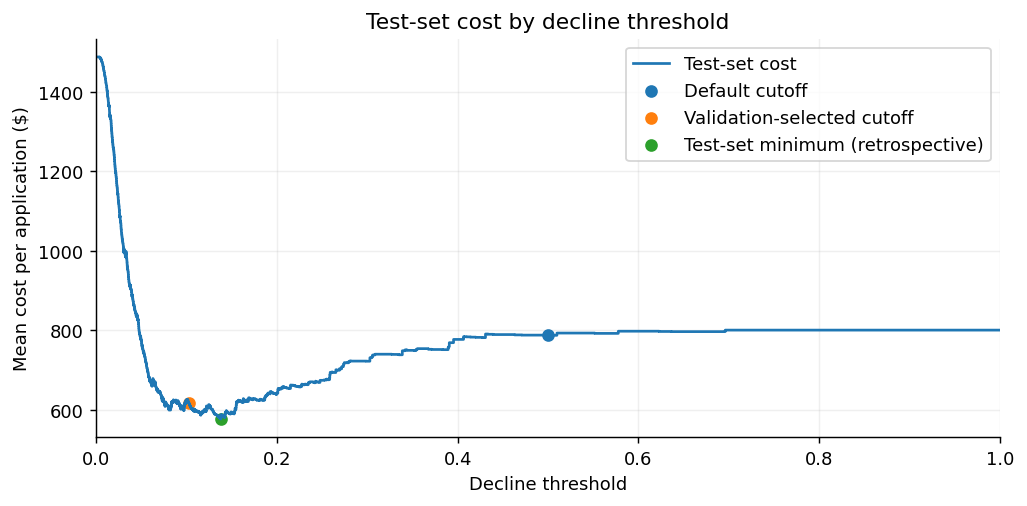

In [ ]:
plt.figure(figsize=(8, 4))
plt.step(test_costs.index, test_costs.values, where="pre", label="Test-set cost")
for policy in ["Default cutoff", "Validation-selected cutoff", "Test-set minimum (retrospective)"]:
    row = policy_results.loc[policy]
    plt.scatter(row["Threshold"], row["Cost per application ($)"], label=policy)

plt.xlim(0, 1)
plt.xlabel("Decline threshold")
plt.ylabel("Mean cost per application ($)")
plt.title("Test-set cost by decline threshold")
plt.legend()
plt.tight_layout()
plt.show()

The cheapest cutoff on the test curve was 13.79%, or 36.21
percentage points below 50%. At that cutoff, LASSO caught 82
defaults instead of 3 and missed 117 instead of 196. It declined
241 good applications instead of 3 and approved 2,560 good
applications instead of 2,798. The average cost was \$576.64 per
application. I used the test outcomes to find this minimum, so
that cost is likely optimistic for new applicants.

The cutoff I picked before seeing the test outcomes was 10.23%,
39.77 percentage points below 50%. On the test set it caught 100
defaults and missed 99. It declined 443 good applicants and
approved 2,358. The cost was \$616.87 per application. That's
170.24 dollars less (21.6%) than at the 50% cutoff and also below
the 800.20 dollars per application it would cost to approve everyone.

### Changing the cost of a missed default

I changed the loss given default and kept the interest margin and
reputation cost fixed. Because the 150-dollar charge is the same
for every borrower, the ratio of the two error costs depends on loan
size. I report the ratio for a \$15,000 loan. For the costs
themselves, I still use the amount each applicant requested.

,Loss given default,"FN / FP cost at $15,000",Validation cutoff,Test minimum cutoff,Test cost at validation cutoff ($)
0,0.30,3.3333,0.2210,0.1860,346.7040
1,0.45,5.0000,0.1389,0.1379,471.6557
2,0.60,6.6667,0.1023,0.1379,616.8727
3,0.75,8.3333,0.1023,0.0810,711.9927
4,0.90,10.0000,0.1023,0.0810,807.1127


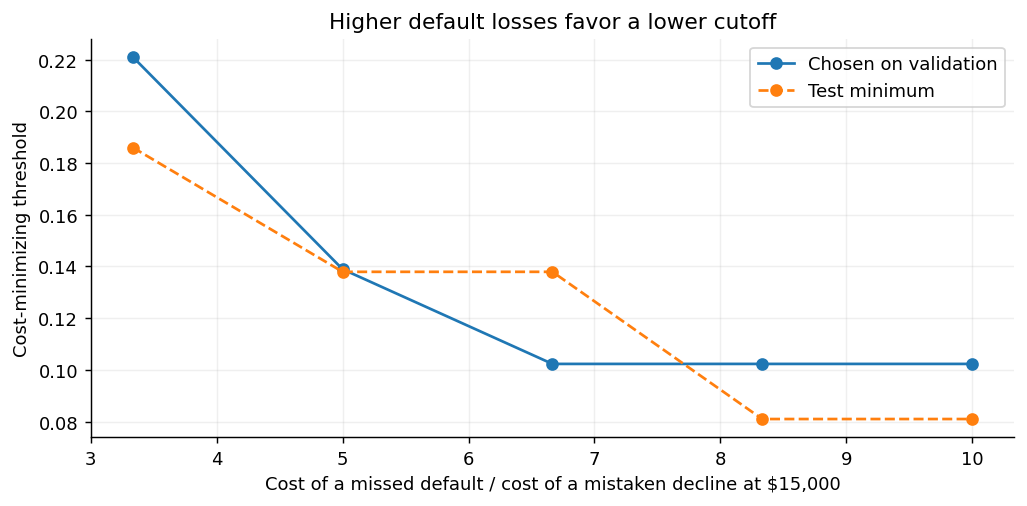

In [ ]:
reference_amount = 15_000
scenarios = []

for rate in [0.30, 0.45, 0.60, 0.75, 0.90]:
    val_best = threshold_costs(y_val, val_scores, val_amount, rate).idxmin()
    test_best = threshold_costs(y_test, test_scores, test_amount, rate).idxmin()
    fp_cost = interest_margin * reference_amount + reputation_cost
    ratio = (rate * reference_amount) / fp_cost
    test_cost = cost_at_cutoff(y_test, test_scores, test_amount, val_best, rate)
    scenarios.append([rate, ratio, val_best, test_best, test_cost])

sensitivity = pd.DataFrame(scenarios, columns=[
    "Loss given default", "FN / FP cost at $15,000", "Validation cutoff",
    "Test minimum cutoff", "Test cost at validation cutoff ($)",
])
display(sensitivity.round(4))

ratios = sensitivity["FN / FP cost at $15,000"]
plt.figure(figsize=(8, 4))
plt.plot(ratios, sensitivity["Validation cutoff"], "o-", label="Chosen on validation")
plt.plot(ratios, sensitivity["Test minimum cutoff"], "o--", label="Test minimum")
plt.xlabel("Cost of a missed default / cost of a mistaken decline at $15,000")
plt.ylabel("Cost-minimizing threshold")
plt.title("Higher default losses favor a lower cutoff")
plt.legend()
plt.tight_layout()
plt.show()

For a \$15,000 loan, I varied the cost of missing a default from
3.33 to 10 times the cost of turning down a good applicant. The
cutoff chosen on validation fell from 22.10% to 10.23%. The test
minimum fell from 18.60% to 8.10%. Some cost changes left the
cutoff where it was because the same group of declines stayed
cheapest.

I'd tell the head of risk to lower the cutoff when missing a
default gets more expensive relative to turning down a good loan.
If it gets more expensive to turn down good loans, raise the
cutoff. Use the lender's own costs, pick the cutoff on validation
data, and then check it on the test set.

With a calibrated probability of default $p$, approving the loan
costs $p C_{FN}$ in expectation and declining it costs
$(1-p)C_{FP}$. The lender should decline when the expected cost
of approval is at least as high as the expected cost of declining.
That gives this probability cutoff.

$$
p^* = \frac{C_{FP}}{C_{FN} + C_{FP}}.
$$

On the reference loan, missing a default costs 9,000 dollars and
turning down a good borrower costs 1,350 dollars. With a calibrated
probability the theoretical cutoff is 13.04%. The cutoffs I found
by searching the cost curves each apply to all loan sizes. They
depend on this portfolio, the model's scores, and the costs I used.



### Task 4.1 A. Does the random forest beat LASSO on accuracy?

The AI suggested McNemar’s test. I checked that the two sets of predictions matched y_test row by row for all 3,000 applicants. The models were both predicting the same set of applicants so I looked at the cases where one model was right and the other was wrong.

The forest got 6 right (b=6) and LASSO got 4 right (c=4). With only 10 discordant cases we used the exact two sided McNemar test. If the models are equally accurate then each has a 50% chance of being the one that correctly identified the discordant case. The p-value was 0.7539 so I'd stick with my Step 2.2 conclusion. Two extra correct predictions gives us very little evidence that the forest is any more accurate.

Approx 7% of applicants defaulted and accuracy counts a missed default and a mistaken decline as one error each. To work out which model would be the cheaper one for the lender we'd go ahead and bootstrap the same applicants as paired rows and compare their dollar losses.

In [ ]:
import numpy as np  # Work with the existing labels and predictions.
from scipy.stats import binomtest, chi2  # Run the exact or approximate test.

forest_pred = rf.predict_proba(X_test)[:, 1] >= 0.5  # Apply the Phase 2 forest cutoff.
lasso_pred = test_scores >= 0.5  # Apply the same cutoff to LASSO.

actual = np.asarray(y_test).ravel()  # Get the true labels in test-row order.
forest = np.asarray(forest_pred).ravel()  # Get the random forest predictions.
lasso = np.asarray(lasso_pred).ravel()  # Get the penalised logistic predictions.

forest_right = forest == actual  # Mark correct forest predictions.
lasso_right = lasso == actual  # Mark correct LASSO predictions.

b = np.sum(forest_right & ~lasso_right)  # Count rows only the forest got right.
c = np.sum(~forest_right & lasso_right)  # Count rows only LASSO got right.
discordant = b + c  # Count rows where exactly one model was correct.

both_right = np.sum(forest_right & lasso_right)  # Count cases both models got right.
both_wrong = np.sum(~forest_right & ~lasso_right)  # Count cases both models got wrong.
paired_table = pd.DataFrame(  # Put the four counts in a paired table.
    [[both_right, b], [c, both_wrong]],  # Supply the counts in row order.
    index=["Forest right", "Forest wrong"],  # Label the forest outcomes.
    columns=["LASSO right", "LASSO wrong"],  # Label the LASSO outcomes.
)
display(paired_table)  # Show the agreement table before running the test.

if discordant == 0:  # The models got the same rows right.
    p_value = 1.0  # There is no evidence of a difference.
elif discordant < 25:  # Use the exact test for a small number of discordant rows.
    p_value = binomtest(b, discordant, p=0.5).pvalue  # Get the two-sided p-value.
else:  # Use the continuity-corrected chi-square approximation.
    statistic = max(abs(b - c) - 1, 0)**2 / discordant  # Compute the corrected statistic.
    p_value = chi2.sf(statistic, df=1)  # Get the two-sided test's p-value.

forest_wins = b > c and p_value < 0.05  # Check whether the forest wins at the 5% level.
print(f"b = {b}, c = {c}, b + c = {discordant}")  # Report the paired counts.
print(f"p = {p_value:.4f}; significant forest advantage: {forest_wins}")  # Report the result.

,LASSO right,LASSO wrong
Forest right,2797,6
Forest wrong,4,193


b = 6, c = 4, b + c = 10
p = 0.7539; significant forest advantage: False



### Task 4.1 B. Does the cutoff hold up after checking calibration?

The AI’s example split the test rows because my prompt only gave it test labels and scores. It also warned that this would be a problem if I’d already used those results in Phase 3. I’d already looked at the test cost curve, so I used the notebook’s separate validation set.

I fit Platt scaling and isotonic regression on one half of the validation set. On the other half, I compared their Brier scores and found the cutoffs that minimized cost using the same assumptions as in Phase 3. Then I applied the fitted calibrators and their cutoffs to the original test set.

I checked the 10.23% cutoff because that was the policy I chose on validation data in Phase 3. The 13.79% cutoff came from the test cost curve, so I kept it as a hindsight benchmark.

Raw LASSO validation Brier = 0.054547
Platt validation Brier = 0.054285
Isotonic validation Brier = 0.055494

Raw LASSO test Brier = 0.056401
Reliability = 0.000226, resolution = 0.005230
Uncertainty = 0.061933, binned Brier = 0.056929
Grouping adjustment = -0.000528

Platt test Brier = 0.056351
Reliability = 0.000140, resolution = 0.005230
Uncertainty = 0.061933, binned Brier = 0.056844
Grouping adjustment = -0.000493

Isotonic test Brier = 0.058969
Reliability = 0.000209, resolution = 0.005230
Uncertainty = 0.061933, binned Brier = 0.056912
Grouping adjustment = +0.002057


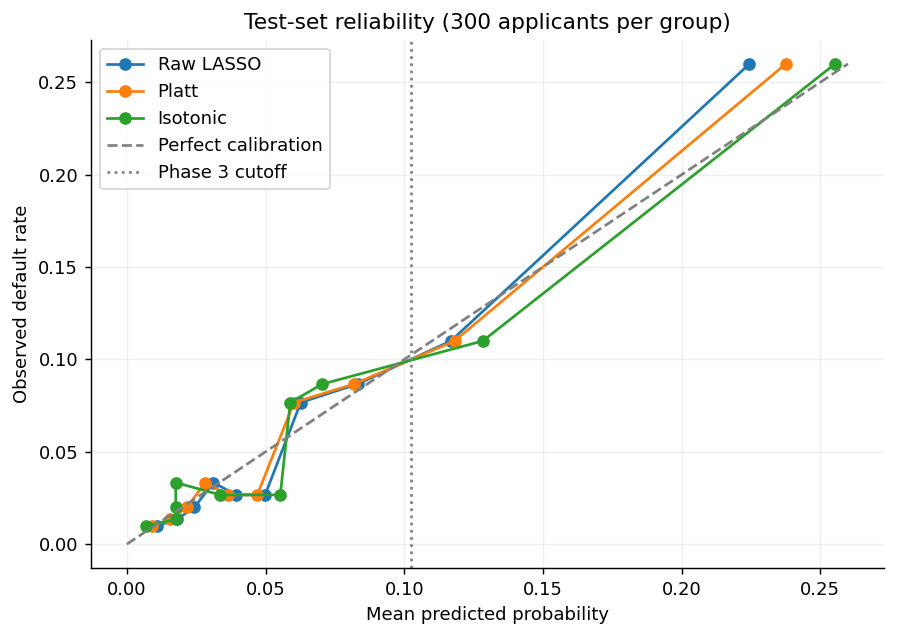

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import brier_score_loss
from sklearn.model_selection import train_test_split

y_prob = test_scores  # Start with the original LASSO test probabilities.
actual = np.asarray(y_test).ravel()
raw = np.asarray(y_prob).ravel()
val_actual = np.asarray(y_val).ravel()
val_prob = np.asarray(val_scores).ravel()

# Fit calibrators on half the validation set and compare them on the other half.
fit_rows, check_rows = train_test_split(
    np.arange(len(val_actual)), test_size=0.5, stratify=val_actual, random_state=seed
)

def log_odds(prob):
    prob = np.clip(prob, 1e-8, 1 - 1e-8)
    return np.log(prob / (1 - prob)).reshape(-1, 1)

platt = LogisticRegression(**no_penalty)  # Reuse the Phase 2 settings.
platt.fit(log_odds(val_prob[fit_rows]), val_actual[fit_rows])

isotonic = IsotonicRegression(out_of_bounds="clip")
isotonic.fit(val_prob[fit_rows], val_actual[fit_rows])

def predictions(prob):
    return {
        "Raw LASSO": prob,
        "Platt": platt.predict_proba(log_odds(prob))[:, 1],
        "Isotonic": isotonic.predict(prob),
    }

for name, prob in predictions(val_prob[check_rows]).items():
    score = brier_score_loss(val_actual[check_rows], prob)
    print(f"{name} validation Brier = {score:.6f}")

# Keep the same applicants in each group when comparing the three methods.
groups = np.array_split(np.argsort(raw), 10)
sizes = np.array([len(group) for group in groups])
weights = sizes / len(actual)
observed = np.array([actual[group].mean() for group in groups])

default_rate = actual.mean()
uncertainty = default_rate * (1 - default_rate)
resolution = np.sum(weights * (observed - default_rate)**2)

plt.figure(figsize=(7, 5))
plot_max = observed.max()

for name, prob in predictions(raw).items():
    predicted = np.array([prob[group].mean() for group in groups])
    reliability = np.sum(weights * (predicted - observed)**2)
    binned_brier = reliability - resolution + uncertainty
    brier = brier_score_loss(actual, prob)
    adjustment = brier - binned_brier

    print(f"\n{name} test Brier = {brier:.6f}")
    print(f"Reliability = {reliability:.6f}, resolution = {resolution:.6f}")
    print(f"Uncertainty = {uncertainty:.6f}, binned Brier = {binned_brier:.6f}")
    print(f"Grouping adjustment = {adjustment:+.6f}")

    plt.plot(predicted, observed, "o-", label=name)
    plot_max = max(plot_max, predicted.max())

plt.plot([0, plot_max], [0, plot_max], "--", color="gray", label="Perfect calibration")
plt.axvline(val_cutoff, color="gray", linestyle=":", label="Phase 3 cutoff")
plt.xlabel("Mean predicted probability")
plt.ylabel("Observed default rate")
plt.title(f"Test-set reliability ({sizes.min()} applicants per group)")
plt.legend()
plt.tight_layout()
plt.show()

I've kept the 10.23% cut-off from Phase 3 for this simulation. Of the 300 applicants in the score group that included the cut-off, the model predicted an average default rate of 11.68%. The real rate was 11.00%. The 95% CI was 7.94% to 15.05% so that's a decent check on calibration right at the cut-off.

The original rule also had the lowest test cost at $616.87 per application. After retuning the Platt rule was at 626.37 per application at an 18.99% cutoff and the isotonic rule was at 620.41 at a 21.05% cutoff.

AI Transcript

Model: GPT-6 Sol

Date: November 23, 2026

* Prompt:

[Prep] Act as a model risk analyst comparing two candidate credit
models before one goes into production.

[Request] I have two fitted classifiers scored on my test set. The
random forest got 0.9?? accuracy and the penalised logistic model got
0.9??. Write Python that tells me whether the forest is significantly
better, and give me a p-value.

[Iterate] numpy, pandas and scipy only. Reuse my y_test, my two
prediction arrays, and nothing else.

[Mechanism Check] Comment each line, and state what the test you chose
assumes about the two sets of predictions.

[Evaluate] One sentence I can put in front of the head of risk.

* Reply:

import numpy as np  # Compare the labels row by row.
from scipy.stats import binomtest  # Compute the exact binomial tail probability.

y = np.asarray(y_test)  # Read the true class labels in test-set order.
rf = np.asarray(y_pred_rf)  # Read the random forest's predicted labels.
logit = np.asarray(y_pred_logit)  # Read the penalised logistic model's predicted labels.
if y.ndim != 1 or y.size == 0 or not (y.shape == rf.shape == logit.shape):  # Check input shapes.
    raise ValueError("Expected three nonempty, aligned 1-D arrays.")  # Prevent unintended broadcasting.

rf_correct = rf == y  # Mark the rows the forest classified correctly.
logit_correct = logit == y  # Mark the rows the logistic model classified correctly.
rf_only = np.count_nonzero(rf_correct & ~logit_correct)  # Count rows only the forest got right.
logit_only = np.count_nonzero(logit_correct & ~rf_correct)  # Count rows only the logistic model got right.
discordant = rf_only + logit_only  # Count rows where exactly one model was correct.

if discordant:  # Test whether the discordant rows favour the forest.
    p_value = binomtest(rf_only, discordant, p=0.5, alternative="greater").pvalue  # Use the upper tail.
else:  # The models had the same correctness outcome on every row.
    p_value = 1.0  # With zero discordant rows, use a p-value of 1.

gap_pp = 100 * (rf_only - logit_only) / y.size  # Express the accuracy gap in percentage points.
if p_value <= 0.05:  # Apply the 5% significance level.
    evidence = "supports a forest accuracy advantage"  # Describe a significant result.
else:  # The p-value exceeds the significance threshold.
    evidence = "provides insufficient evidence of a forest accuracy advantage"  # Describe the result.

print(  # Print one sentence for the head of risk.
    f"The forest’s test-set accuracy difference versus penalised logistic regression was "  # Name the models.
    f"{gap_pp:+.2f} percentage points, and the paired test {evidence} at the 5% level "  # Give the gap and decision.
    f"(one-sided p = {p_value:.6g})."  # Report the p-value.
)  # End the print call.

* Prompt:

[Prep] Act as a model risk analyst at a bank, reviewing a credit
scoring model before it goes into production.

[Request] I have a fitted classifier producing default probabilities
on a test set with about 7% prevalence. Write Python that assesses
CALIBRATION -- a reliability diagram binning predicted probability
against observed frequency, plus the Brier score and its
decomposition -- and then applies both Platt scaling and isotonic
regression, reporting whether either improves calibration.

[Iterate] scikit-learn, numpy, matplotlib. Reuse my y_test and
y_prob. Handle the sparse high-probability bins that low prevalence
creates rather than letting them produce a misleading plot.

[Mechanism Check] Explain why a model can rank applicants correctly --
high AUC -- and still be badly calibrated, and why that distinction
decides whether my cost-optimal threshold is trustworthy.

[Evaluate] Given my reliability diagram, is my Phase 3 threshold
valid? If not, what should I do before using it?


* Reply:

import matplotlib.pyplot as plt
import numpy as np
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold

y = np.asarray(y_test)
p = np.asarray(y_prob, dtype=float)
if y.ndim != 1 or y.size == 0 or p.shape != y.shape:
    raise ValueError("Pass aligned 1-D arrays of labels and default probabilities.")
if not np.isin(y, [0, 1]).all() or not np.all((0 <= p) & (p <= 1)):
    raise ValueError("Use 1 for default, 0 otherwise, and probabilities in [0, 1].")

y = y.astype(int)
n_splits = min(5, np.bincount(y, minlength=2).min())
if n_splits < 2:
    raise ValueError("Cross-fitting requires at least two observations of each class.")

# Fit on one set of rows and transform the held-out rows.
p_clip = np.clip(p, 1e-6, 1 - 1e-6)
log_odds = (np.log(p_clip) - np.log1p(-p_clip))[:, None]
platt = np.empty_like(p)
isotonic = np.empty_like(p)
folds = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=42)

for fit, evaluate in folds.split(p, y):
    sigmoid = LogisticRegression(C=1e6).fit(log_odds[fit], y[fit])
    monotone = IsotonicRegression(out_of_bounds="clip").fit(p[fit], y[fit])
    platt[evaluate] = sigmoid.predict_proba(log_odds[evaluate])[:, 1]
    isotonic[evaluate] = monotone.predict(p[evaluate])


def reliability_bins(prob, min_count=50, max_bins=10):
    # Aim for equal counts without splitting ties or leaving a tiny tail bin.
    target = max(min_count, int(np.ceil(prob.size / max_bins)))
    values, counts = np.unique(prob, return_counts=True)
    cuts, last_cut = [], 0
    for value, end in zip(values, counts.cumsum()):
        if end - last_cut >= target and prob.size - end >= target:
            cuts.append(value)
            last_cut = end
    return np.searchsorted(cuts, prob, side="left")


prevalence = y.mean()
uncertainty = prevalence * (1 - prevalence)
scores = {}
print(f"Default prevalence: {prevalence:.2%} ({y.sum()}/{y.size})")

fig, axes = plt.subplots(
    1, 3, figsize=(13, 4), sharex=True, sharey=True, layout="constrained"
)
axis_max = 0.0

for ax, (name, prob) in zip(axes, [("Raw", p), ("Platt", platt), ("Isotonic", isotonic)]):
    b = reliability_bins(prob)
    n = np.bincount(b)
    defaults = np.bincount(b, weights=y).astype(int)
    mean_p = np.bincount(b, weights=prob) / n
    observed = defaults / n
    weights = n / y.size

    brier = np.mean((prob - y)**2)
    rel = weights @ (mean_p - observed)**2
    res = weights @ (observed - prevalence)**2
    within_p = prob - mean_p[b]
    within_y = y - observed[b]
    adjustment = np.mean(within_p**2 - 2 * within_p * within_y)
    scores[name] = (brier, rel)
    print(f"\n{name}  Brier={brier:.6f}  REL={rel:.6f}  RES={res:.6f} "
          f" UNC={uncertainty:.6f}  Adjustment={adjustment:+.6f}")

    # Vertical lines are Wilson intervals. Horizontal lines show the score span.
    z = 1.96
    denominator = 1 + z**2 / n
    centre = (observed + z**2 / (2 * n)) / denominator
    half_width = z * np.sqrt(observed * (1 - observed) / n + z**2 / (4 * n**2))
    half_width /= denominator
    lo = np.full(n.size, np.inf)
    hi = np.full(n.size, -np.inf)
    np.minimum.at(lo, b, prob)
    np.maximum.at(hi, b, prob)

    ax.plot([0, 1], [0, 1], "--", color="0.6")
    ax.hlines(observed, lo, hi, color="C0", alpha=0.4)
    ax.vlines(mean_p, centre - half_width, centre + half_width, color="C0", alpha=0.6)
    ax.scatter(mean_p, observed, color="C0", zorder=3)
    ax.set(title=name, xlabel="Mean predicted default probability")
    axis_max = max(axis_max, mean_p.max(), (centre + half_width).max())

    print("  Score range          Mean PD    Observed PD   Defaults/n")
    for left, right, x, rate, d, count in zip(lo, hi, mean_p, observed, defaults, n):
        print(f"  {left:7.2%}–{right:7.2%}   {x:8.2%}    {rate:8.2%}   {d:4d}/{count}")

limit = min(1.02, 1.08 * axis_max)
axes[0].set(xlim=(-0.01 * limit, limit), ylim=(-0.01 * limit, limit),
            ylabel="Observed default frequency")

print("\nCross-fitted comparison with raw probabilities")
for name in ("Platt", "Isotonic"):
    delta_bs, delta_rel = np.subtract(scores[name], scores["Raw"])
    lower_bs, lower_rel = delta_bs < -1e-10, delta_rel < -1e-10
    if lower_bs and lower_rel:
        result = "lower Brier and lower binned reliability error"
    elif lower_rel:
        result = "lower binned reliability error, with Brier flat or higher"
    elif lower_bs:
        result = "lower Brier, with calibration improvement unclear"
    else:
        result = "both measures flat or higher"
    print(f"{name} vs raw: ΔBrier={delta_bs:+.6f}, ΔREL={delta_rel:+.6f} | {result}")

plt.show()


REL measures squared calibration error at the bin level. RES measures how much observed default rates differ across bins, and UNC is the variance implied by overall default prevalence. The exact identity is Brier = REL − RES + UNC + Adjustment, where Adjustment accounts for variation within bins. A lower REL and points closer to the diagonal support a calibration improvement. Read both together because the bin boundaries can differ by method and Brier also reflects resolution. I checked the code on simulated data with sparse tail scores and ties. Your arrays determine which method improves on your sample.

Why AUC and calibration lead to different decisions. AUC measures ranking. Doubling every predicted probability below 50% preserves its rank while turning a 5% estimate into 10%. Calibration asks whether applicants scored at 10% actually default about 10% of the time. With constant false-positive and false-negative costs and zero cost for correct decisions, the cost-optimal rule flags default risk above \(C_{\mathrm{FP}}/(C_{\mathrm{FP}}+C_{\mathrm{FN}})\). Biased probabilities near that cutoff can put applicants on the wrong side of the cost trade-off even when AUC is high. If Phase 3 instead chose an empirical score cutoff, validate its realised costs directly on the score scale it was chosen for.

###Task 4.2: The recommendation


I'd hold off on signing. On the simulated test set, approving everyone was already at 93.37%. LASSO was at 50% on the same set.

I'd take LASSO forward for validation at the 10.23% decline cut-off. At that cut-off it picked up 100 of the 199 defaults and rejected 443 people who would have repaid. The estimated cost went down from $800.20 to $616.87 per application as opposed to approving everyone. That's a saving of $183.33 per application or about 23%. Both the recalibrated rules ended up costing more on the same test set.

I went with the cutoff on the validation data. I assumed a missed default cost us 60% of the loan principal and that turning down a good applicant cost us 8% of principal in lost interest margin plus $150 in lost goodwill.

I'd sign if that same cut-off delivered tangible savings over the alternative of approving everyone on a new, representative sample with known repayment outcomes and using the lender's own cost estimates.

